 These are the libraries I need for checking the data, making charts,
 preparing the features, and run the clustering algorithms

In [92]:
%matplotlib inline
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
print("Libraries imported successfully.")

Libraries imported successfully.


In [93]:
data = pd.read_csv("data/financial_transactions.csv")
print("Dataset shape:", data.shape)
print("\nfirst five transactions:")
display(data.head())
print("\ncolumn names:")
print(data.columns.tolist())
print("\ndata types and missing values:")
data.info()
print("\nmissing values in each column:")
print(data.isnull().sum())
print("\nnumber of duplicate rows:", data.duplicated().sum())

Dataset shape: (100000, 6)

first five transactions:


,transaction_id,date,customer_id,amount,type,description
0,1,2020-10-26,926,6478.39,credit,Expect series shake art again our.
1,2,2020-01-08,466,1255.95,credit,Each left similar likely coach take.
2,3,2019-09-02,110,7969.68,debit,Direction wife job pull determine leader move ...
3,4,2020-12-02,142,2927.41,credit,Agree reveal buy black already.
4,5,2020-12-02,944,4661.88,debit,Child relationship show college whom speech.



column names:
['transaction_id', 'date', 'customer_id', 'amount', 'type', 'description']

data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   transaction_id  100000 non-null  int64  
 1   date            100000 non-null  str    
 2   customer_id     100000 non-null  int64  
 3   amount          100000 non-null  float64
 4   type            100000 non-null  str    
 5   description     100000 non-null  str    
dtypes: float64(1), int64(2), str(3)
memory usage: 9.6 MB

missing values in each column:
transaction_id    0
date              0
customer_id       0
amount            0
type              0
description       0
dtype: int64

number of duplicate rows: 0


In [94]:
required_columns = ["customer_id", "amount", "type"]
missing_columns = [
    col for col in required_columns
    if col not in data.columns
]
if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}. "
        f"Available columns: {data.columns.tolist()}"
    )
data = data.copy()
data.columns = data.columns.str.strip()
data = data.drop_duplicates()
data["customer_id"] = data["customer_id"].astype("string").str.strip()
data["amount"] = pd.to_numeric(data["amount"], errors="coerce")
data["type"] = data["type"].astype("string").str.strip()
data = data.dropna(subset=required_columns)
data = data[data["customer_id"] != ""]
data = data[data["amount"] >= 0]
data = data[data["type"] != ""]
print("Rows after cleaning:", len(data))
print("Unique customers:", data["customer_id"].nunique())
display(data.head())
os.makedirs("outputs/charts", exist_ok=True)
data.to_csv("outputs/cleaned_transactions.csv", index=False)

Rows after cleaning: 100000
Unique customers: 1000


,transaction_id,date,customer_id,amount,type,description
0,1,2020-10-26,926,6478.39,credit,Expect series shake art again our.
1,2,2020-01-08,466,1255.95,credit,Each left similar likely coach take.
2,3,2019-09-02,110,7969.68,debit,Direction wife job pull determine leader move ...
3,4,2020-12-02,142,2927.41,credit,Agree reveal buy black already.
4,5,2020-12-02,944,4661.88,debit,Child relationship show college whom speech.


Transaction amount statistics:


,amount
count,100000.000000
mean,5009.012768
std,2888.443654
min,1.290000
25%,2514.572500
50%,5006.135000
75%,7513.840000
max,10000.000000



Transaction types:


,Transaction Type,Count
0,credit,33371
1,transfer,33331
2,debit,33298



Total transaction amount: 500901276.83
Average transaction amount: 5009.01
Median transaction amount: 5006.14


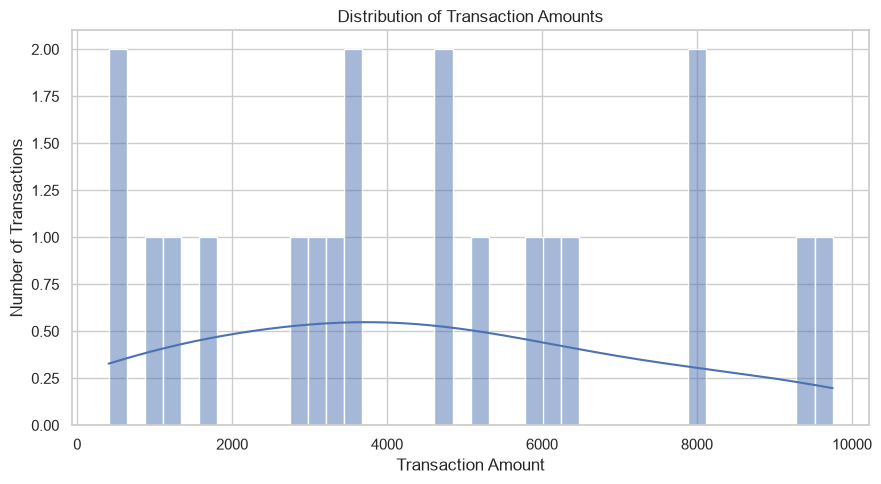

In [95]:
print("Transaction amount statistics:")
display(data["amount"].describe().to_frame())
print("\nTransaction types:")
display(
    data["type"]
    .value_counts()
    .rename_axis("Transaction Type")
    .reset_index(name="Count")
)
print("\nTotal transaction amount:", round(data["amount"].sum(), 2))
print("Average transaction amount:", round(data["amount"].mean(), 2))
print("Median transaction amount:", round(data["amount"].median(), 2))
plt.figure(figsize=(9, 5))
sns.histplot(data=data.head(20), x="amount", bins=40, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig(
    "outputs/charts/transaction_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

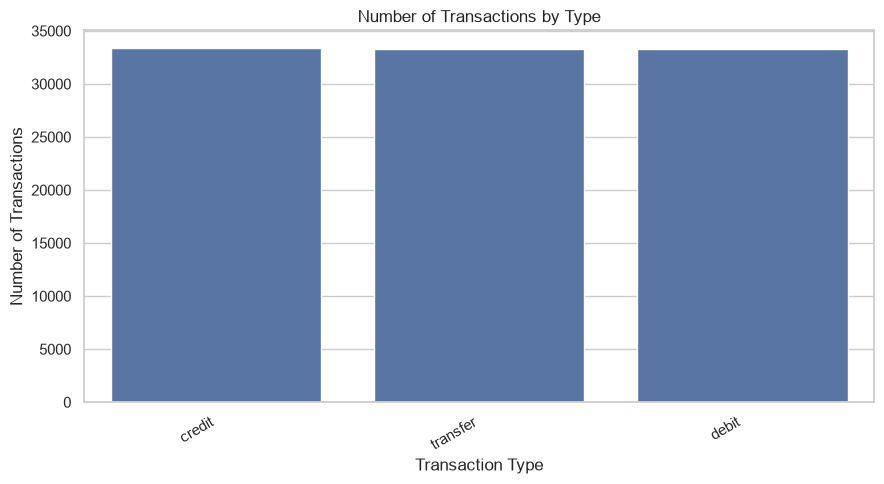

In [96]:
type_counts = data["type"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=type_counts.index,
    y=type_counts.values
)

plt.title("Number of Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "outputs/charts/transaction_types.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [97]:
customer_features = data.groupby("customer_id").agg(
    transaction_count=("amount", "count"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean"),
    median_amount=("amount", "median"),
    amount_std=("amount", "std")
)

customer_features["amount_std"] = (
    customer_features["amount_std"].fillna(0)
)

type_features = pd.crosstab(
    data["customer_id"],
    data["type"]
)

type_features.columns = [
    f"type_{str(col).strip().replace(' ', '_')}"
    for col in type_features.columns
]

customer_features = customer_features.join(
    type_features,
    how="left"
).fillna(0)

customer_features = customer_features.reset_index()

print("Customer-level dataset shape:", customer_features.shape)
display(customer_features.head())

customer_features.to_csv(
    "outputs/customer_features.csv",
    index=False
)

Customer-level dataset shape: (1000, 9)


,customer_id,transaction_count,total_amount,average_amount,median_amount,amount_std,type_credit,type_debit,type_transfer
0,1,97,481760.83,4966.606495,4997.71,2927.494327,38,29,30
1,10,91,487735.23,5359.727802,5558.84,2718.928524,32,32,27
2,100,95,532768.01,5608.084316,6331.41,2797.800041,38,30,27
3,1000,105,529241.20,5040.392381,4884.63,2739.242947,35,28,42
4,101,99,506584.37,5117.013838,5215.82,2855.022356,33,31,35


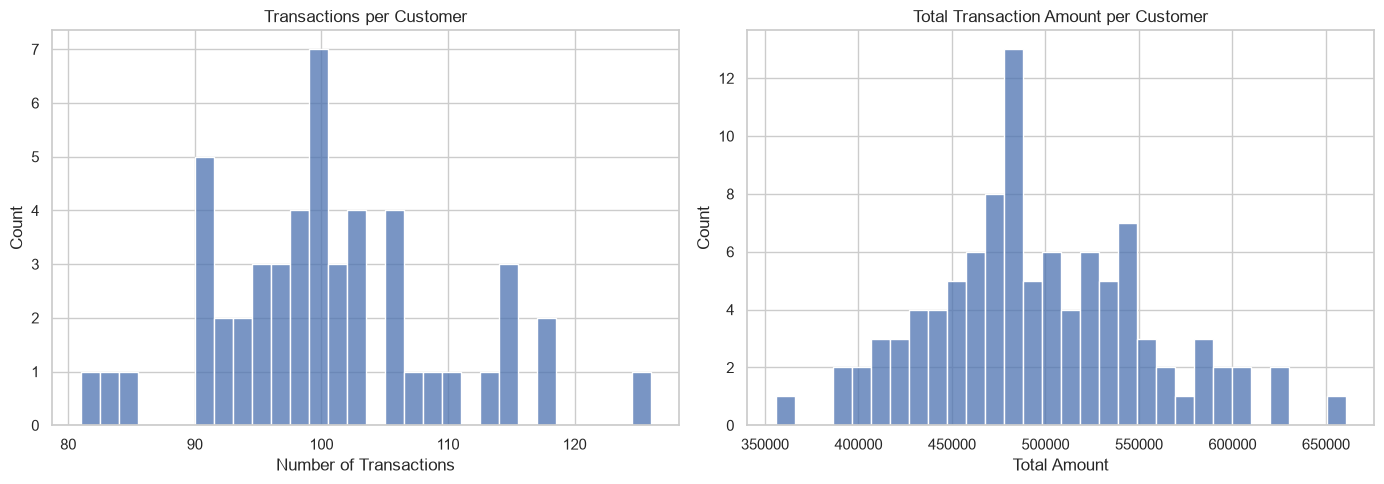

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=customer_features.head(50),
    x="transaction_count",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Transactions per Customer")
axes[0].set_xlabel("Number of Transactions")

sns.histplot(
    data=customer_features.head(100),
    x="total_amount",
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Total Transaction Amount per Customer")
axes[1].set_xlabel("Total Amount")

plt.tight_layout()

plt.savefig(
    "outputs/charts/customer_behavior.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [99]:
feature_columns = [
    col for col in customer_features.columns
    if col != "customer_id"
]

X = customer_features[feature_columns].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Number of customers:", X_scaled.shape[0])
print("Number of clustering features:", X_scaled.shape[1])
print("Scaled feature matrix shape:", X_scaled.shape)

scaled_data = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=customer_features["customer_id"]
)

display(scaled_data.head())

Number of customers: 1000
Number of clustering features: 8
Scaled feature matrix shape: (1000, 8)


,transaction_count,total_amount,average_amount,median_amount,amount_std,type_credit,type_debit,type_transfer
customer_id,,,,,,,,
1,-0.308960,-0.332752,-0.139795,-0.025746,0.329669,0.851556,-0.750587,-0.564629
10,-0.926880,-0.228888,1.167967,1.068758,-1.268536,-0.252211,-0.226678,-1.073152
100,-0.514933,0.553995,1.994152,2.575684,-0.664157,0.851556,-0.575951,-1.073152
1000,0.514933,0.492682,0.105662,-0.246312,-1.112870,0.299673,-0.925223,1.469461
101,-0.102987,0.098799,0.360552,0.399686,-0.225671,-0.068250,-0.401314,0.282908


In [100]:
if len(customer_features) < 3:
    raise ValueError(
        "At least three customers are needed for this clustering analysis."
    )

linked = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

print("Hierarchical clustering completed.")
print("Linkage matrix shape:", linked.shape)
print("\nFirst five merge operations:")
print(linked[:5])

Hierarchical clustering completed.
Linkage matrix shape: (999, 4)

First five merge operations:
[[4.21000000e+02 9.52000000e+02 2.84603672e-01 2.00000000e+00]
 [8.79000000e+02 9.85000000e+02 3.20313278e-01 2.00000000e+00]
 [1.00000000e+02 8.83000000e+02 3.21584910e-01 2.00000000e+00]
 [2.95000000e+02 5.43000000e+02 3.25221141e-01 2.00000000e+00]
 [8.00000000e+02 8.94000000e+02 3.35364650e-01 2.00000000e+00]]


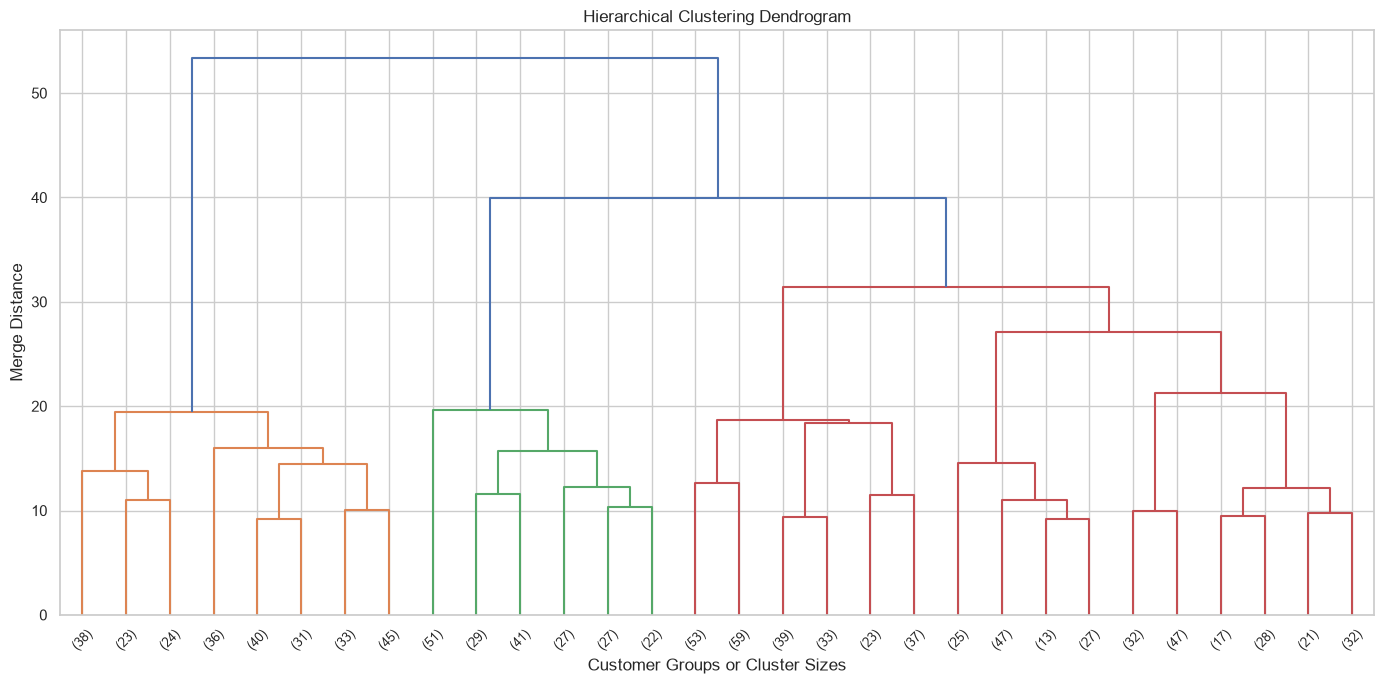

In [101]:
plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups or Cluster Sizes")
plt.ylabel("Merge Distance")
plt.tight_layout()

plt.savefig(
    "outputs/charts/customer_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [102]:
cluster_scores = []

max_clusters = min(6, len(customer_features) - 1)

for k in range(2, max_clusters + 1):
    labels = fcluster(
        linked,
        t=k,
        criterion="maxclust"
    )

    if len(np.unique(labels)) > 1:
        score = silhouette_score(X_scaled, labels)
        cluster_scores.append({
            "n_clusters": k,
            "silhouette_score": score
        })

scores_df = pd.DataFrame(cluster_scores)

if scores_df.empty:
    raise ValueError("Unable to evaluate the selected cluster solutions.")

display(scores_df)

best_k = int(
    scores_df.loc[
        scores_df["silhouette_score"].idxmax(),
        "n_clusters"
    ]
)

print("Best cluster count by silhouette score:", best_k)

,n_clusters,silhouette_score
0,2,0.165472
1,3,0.133453
2,4,0.107308
3,5,0.108952
4,6,0.097176


Best cluster count by silhouette score: 2


In [103]:
customer_features["cluster"] = fcluster(
    linked,
    t=best_k,
    criterion="maxclust"
)

print("Number of clusters found:", customer_features["cluster"].nunique())

print("\nCustomers in each cluster:")
display(
    customer_features["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Customers")
)

customer_features.to_csv(
    "outputs/customer_segments.csv",
    index=False
)

Number of clusters found: 2

Customers in each cluster:


,Cluster,Number of Customers
0,1,270
1,2,730


In [104]:
summary_columns = [
    "transaction_count",
    "total_amount",
    "average_amount",
    "median_amount",
    "amount_std"
]

cluster_summary = (
    customer_features
    .groupby("cluster")
    .agg(
        customer_count=("customer_id", "count"),
        **{
            col: (col, "mean")
            for col in summary_columns
        }
    )
    .round(2)
)

cluster_summary["customer_percentage"] = (
    cluster_summary["customer_count"]
    / len(customer_features)
    * 100
).round(2)

display(cluster_summary)

cluster_summary.to_csv(
    "outputs/cluster_summary.csv"
)

,customer_count,transaction_count,total_amount,average_amount,median_amount,amount_std,customer_percentage
cluster,,,,,,,
1,270,110.47,564637.99,5114.82,5156.66,2879.86,27.0
2,730,96.13,477327.42,4969.35,4957.00,2886.18,73.0


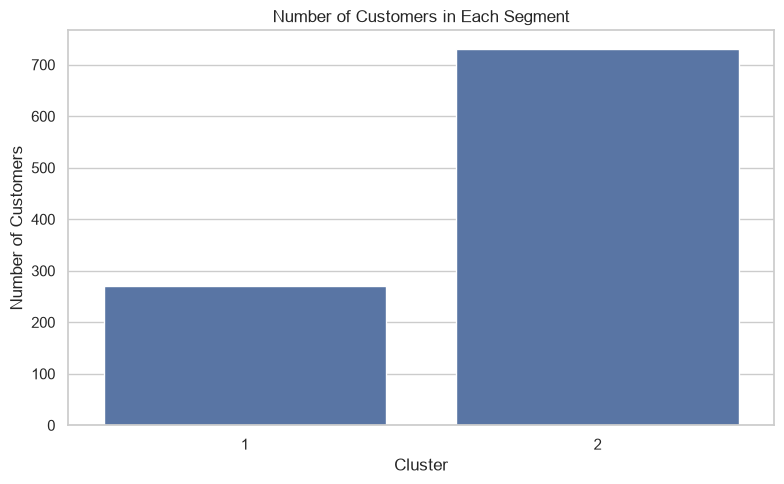

In [105]:
cluster_sizes = (
    customer_features["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_sizes.index.astype(str),
    y=cluster_sizes.values
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "outputs/charts/cluster_sizes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

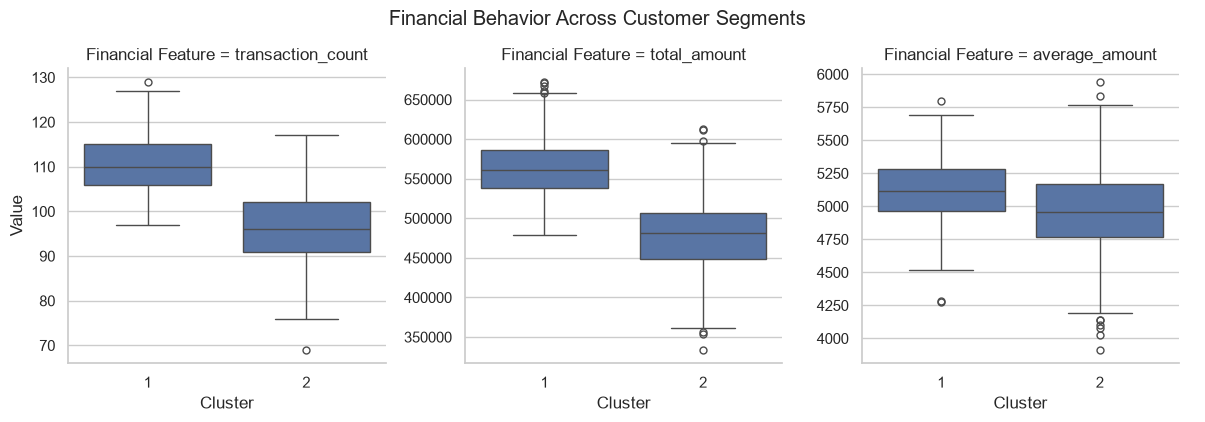

In [106]:
plot_data = customer_features.melt(
    id_vars=["customer_id", "cluster"],
    value_vars=[
        "transaction_count",
        "total_amount",
        "average_amount"
    ],
    var_name="Financial Feature",
    value_name="Value"
)

g = sns.catplot(
    data=plot_data,
    x="cluster",
    y="Value",
    col="Financial Feature",
    kind="box",
    sharey=False,
    height=4,
    aspect=1
)

g.fig.suptitle(
    "Financial Behavior Across Customer Segments",
    y=1.05
)

g.set_axis_labels("Cluster", "Value")

plt.savefig(
    "outputs/charts/cluster_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

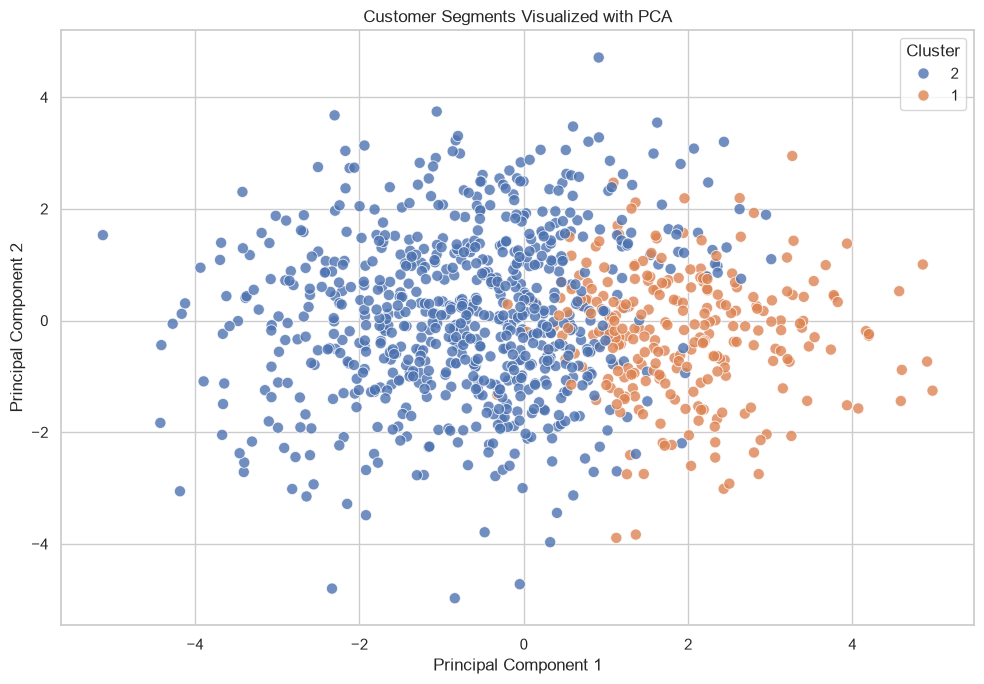

Variance explained by the two components: 60.39 %


In [107]:
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X_scaled)

pca_data = pd.DataFrame({
    "PC1": coordinates[:, 0],
    "PC2": coordinates[:, 1],
    "Cluster": customer_features["cluster"].astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_data,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="deep",
    s=65,
    alpha=0.8
)

plt.title("Customer Segments Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()

plt.savefig(
    "outputs/charts/customer_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(
    "Variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

,type_credit,type_debit,type_transfer
cluster,,,
1,35.45,36.37,38.66
2,32.60,32.16,31.36


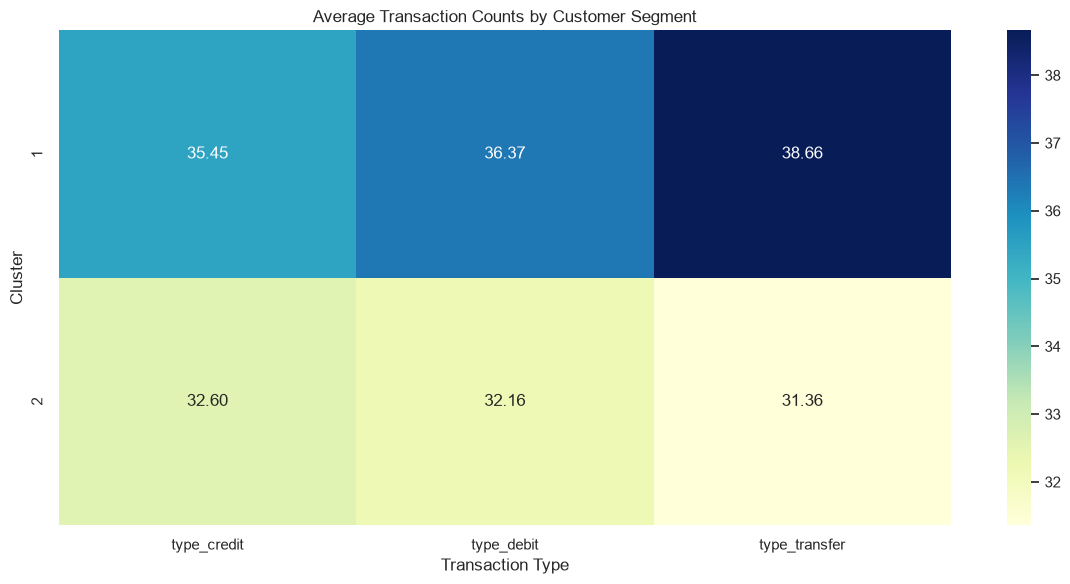

In [108]:
customer_type_data = customer_features[
    ["customer_id", "cluster"]
].merge(
    type_features.reset_index(),
    on="customer_id",
    how="left"
)

type_columns = [
    col for col in type_features.columns
    if col in customer_type_data.columns
]

if type_columns:
    type_by_cluster = (
        customer_type_data
        .groupby("cluster")[type_columns]
        .mean()
        .round(2)
    )

    display(type_by_cluster)

    plt.figure(figsize=(12, 6))

    sns.heatmap(
        type_by_cluster,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu"
    )

    plt.title("Average Transaction Counts by Customer Segment")
    plt.xlabel("Transaction Type")
    plt.ylabel("Cluster")
    plt.tight_layout()

    plt.savefig(
        "outputs/charts/transaction_types_by_cluster.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No transaction-type features are available for comparison.")

In [109]:
segment_report = cluster_summary.copy()

segment_report["interpretation"] = ""

median_transactions = customer_features["transaction_count"].median()
median_total_amount = customer_features["total_amount"].median()

for cluster_id, row in segment_report.iterrows():
    descriptions = []

    if row["transaction_count"] >= median_transactions:
        descriptions.append("more frequent transactions")
    else:
        descriptions.append("less frequent transactions")

    if row["total_amount"] >= median_total_amount:
        descriptions.append("higher total transaction amounts")
    else:
        descriptions.append("lower total transaction amounts")

    segment_report.loc[
        cluster_id, "interpretation"
    ] = "Customers with " + " and ".join(descriptions)

display(segment_report)

segment_report.to_csv(
    "outputs/segment_interpretation.csv"
)

,customer_count,transaction_count,total_amount,average_amount,median_amount,amount_std,customer_percentage,interpretation
cluster,,,,,,,,
1,270,110.47,564637.99,5114.82,5156.66,2879.86,27.0,Customers with more frequent transactions and ...
2,730,96.13,477327.42,4969.35,4957.00,2886.18,73.0,Customers with less frequent transactions and ...


In [110]:
print("PROJECT SUMMARY")
print("-" * 45)

print("Original transaction rows:", len(data))
print("Unique customers:", data["customer_id"].nunique())
print("Number of customer segments:", customer_features["cluster"].nunique())

print("\nCluster sizes:")
print(customer_features["cluster"].value_counts().sort_index())

print("\nCustomer segment summary:")
display(cluster_summary)

print("\nFiles saved in the outputs folder:")
for root, dirs, files in os.walk("outputs"):
    for filename in files:
        print(os.path.join(root, filename))

PROJECT SUMMARY
---------------------------------------------
Original transaction rows: 100000
Unique customers: 1000
Number of customer segments: 2

Cluster sizes:
cluster
1    270
2    730
Name: count, dtype: int64

Customer segment summary:


,customer_count,transaction_count,total_amount,average_amount,median_amount,amount_std,customer_percentage
cluster,,,,,,,
1,270,110.47,564637.99,5114.82,5156.66,2879.86,27.0
2,730,96.13,477327.42,4969.35,4957.00,2886.18,73.0



Files saved in the outputs folder:
outputs\cleaned_transactions.csv
outputs\cluster_summary.csv
outputs\customer_features.csv
outputs\customer_segments.csv
outputs\segment_interpretation.csv
outputs\charts\cluster_comparison.png
outputs\charts\cluster_sizes.png
outputs\charts\customer_behavior.png
outputs\charts\customer_clusters_pca.png
outputs\charts\customer_dendrogram.png
outputs\charts\transaction_distribution.png
outputs\charts\transaction_types.png
outputs\charts\transaction_types_by_cluster.png


In [111]:
customer_features.to_csv(
    "outputs/customer_segments.csv",
    index=False
)

cluster_summary.to_csv(
    "outputs/cluster_summary.csv"
)

data.to_csv(
    "outputs/cleaned_transactions.csv",
    index=False
)

print("Final results saved successfully.")
print("Check the outputs folder for CSV files and charts.")

Final results saved successfully.
Check the outputs folder for CSV files and charts.
